In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

from src.clean import load_and_clean

df_model = load_and_clean("../data/loans_sample.csv.gz")
df_model.shape


(18557, 87)

In [3]:
df_sample = df_model.groupby("grade")
default_grades = df_sample["target"].mean()
grades_count = df_sample["target"].size()


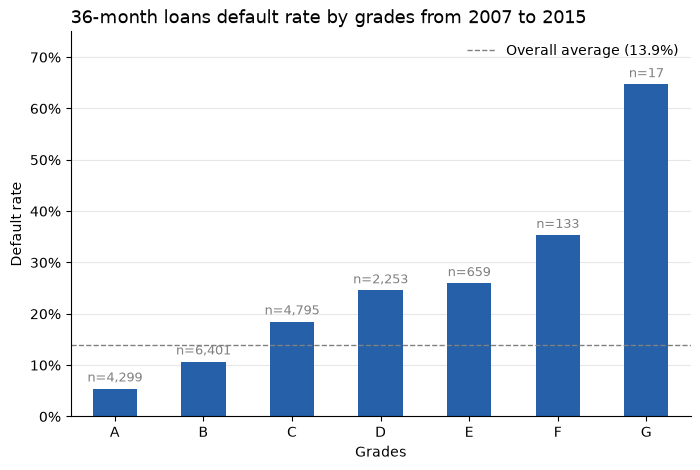

In [15]:
import matplotlib.pyplot as plt 
from matplotlib.ticker import PercentFormatter

ax = default_grades.plot(kind="bar", color = "#2560A9", figsize = (8,5), label = "_nolegend_")
ax.bar_label(ax.containers[0], labels = [f"n={n:,}" for n in grades_count], padding = 3, fontsize = 9, color = "gray")
ax.set_ylim(0,0.75)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

avg = df_model["target"].mean()
ax.axhline(y = avg, linestyle = "--", color = "gray", linewidth = 1, label = f"Overall average ({avg:.1%})")
ax.legend(frameon = False)

plt.title("36-month loans default rate by grades from 2007 to 2015", loc = "left", fontsize = 13)
plt.xlabel("Grades")
plt.ylabel("Default rate")

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xticks(rotation=0)
plt.savefig("../reports/figures/default_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

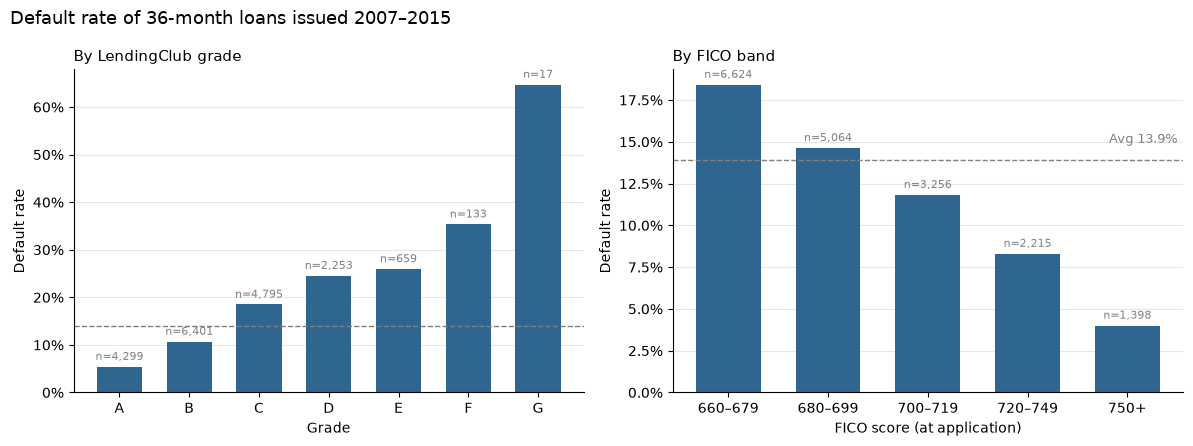

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

bins   = [660, 680, 700, 720, 750, 850]
labels = ["660–679", "680–699", "700–719", "720–749", "750+"]

df_model["fico_band"] = pd.cut(df_model["fico_range_low"], bins=bins, labels=labels, right=False)
df_model.groupby("fico_band", observed=True)["target"].agg(["size", "mean"])

grade_rate = df_model.groupby("grade", observed=True)["target"].agg(["mean", "size"])
fico_rate  = df_model.groupby("fico_band", observed=True)["target"].agg(["mean", "size"])
avg = df_model["target"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

for ax, data, title, xlabel in [
    (axes[0], grade_rate, "By LendingClub grade", "Grade"),
    (axes[1], fico_rate,  "By FICO band",         "FICO score (at application)"),
]:
    bars = ax.bar(data.index.astype(str), data["mean"], color="#2F6690", width=0.65)
    ax.bar_label(bars, labels=[f"n={n:,}" for n in data["size"]], padding=3, fontsize=8, color="gray")
    ax.axhline(avg, linestyle="--", color="gray", linewidth=1)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Default rate")
axes[1].set_ylabel("Default rate")
axes[1].text(len(fico_rate) - 0.5, avg + 0.01, f"Avg {avg:.1%}", color="gray", fontsize=9, ha="right")


fig.suptitle("Default rate of 36-month loans issued 2007–2015", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.savefig("../reports/figures/default_by_grade_and_fico.png", dpi=150, bbox_inches="tight")
plt.show()
